In [1]:
import os

DATA_PATH = "/kaggle/input/datasets/nageshsingh/dna-sequence-dataset"

print("Files in dataset:")
for file in os.listdir(DATA_PATH):
    print(file)

Files in dataset:
dog.txt
example_dna.fa
human.txt
chimpanzee.txt


In [3]:
import pandas as pd

human = pd.read_csv(
    "/kaggle/input/datasets/nageshsingh/dna-sequence-dataset/human.txt",
    sep="\t",
    header=None,
    names=["sequence", "class"]
)

chimpanzee = pd.read_csv(
    "/kaggle/input/datasets/nageshsingh/dna-sequence-dataset/chimpanzee.txt",
    sep="\t",
    header=None,
    names=["sequence", "class"]
)

dog = pd.read_csv(
    "/kaggle/input/datasets/nageshsingh/dna-sequence-dataset/dog.txt",
    sep="\t",
    header=None,
    names=["sequence", "class"]
)

print("Human:", human.shape)
print("Chimpanzee:", chimpanzee.shape)
print("Dog:", dog.shape)

Human: (4381, 2)
Chimpanzee: (1683, 2)
Dog: (821, 2)


In [5]:
# ============================================================
# STEP: Install Biopython and Read DNA FASTA File
# ============================================================

!pip install -q biopython

from Bio import SeqIO

# Dataset path
file_path = "/kaggle/input/datasets/nageshsingh/dna-sequence-dataset/example_dna.fa"

# Read FASTA file
for sequence in SeqIO.parse(file_path, "fasta"):
    print("ID:", sequence.id)
    print("Sequence:", sequence.seq)
    print("Length:", len(sequence))
    print("-" * 60)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 47.7 MB/s eta 0:00:0000:01
ID: ENST00000435737.5
Sequence: ATGTTTCGCATCACCAACATTGAGTTTCTTCCCGAATACCGACAAAAGGAGTCCAGGGAATTTCTTTCAGTGTCACGGACTGTGCAGCAAGTGATAAACCTGGTTTATACAACATCTGCCTTCTCCAAATTTTATGAGCAGTCTGTTGTTGCAGATGTCAGCAACAACAAAGGCGGCCTCCTTGTCCACTTTTGGATTGTTTTTGTCATGCCACGTGCCAAAGGCCACATCTTCTGTGAAGACTGTGTTGCCGCCATCTTGAAGGACTCCATCCAGACAAGCATCATAAACCGGACCTCTGTGGGGAGCTTGCAGGGACTGGCTGTGGACATGGACTCTGTGGTACTAAATGAAGTCCTGGGGCTGACTCTCATTGTCTGGATTGACTGA
Length: 390
------------------------------------------------------------
ID: ENST00000419127.5
Sequence: ATGTTTCGCATCACCAACATTGAGTTTCTTCCCGAATACCGACAAAAGGAGTCCAGGGAATTTCTTTCAGTGTCACGGACTGTGCAGCAAGTGATAAACCTGGTTTATACAACATCTGCCTTCTCCAAATTTTATGAGCAGTCTGTTGTTGCAGATGTCAGCAACAACAAAGGCGGCCTCCTTGTCCACTTTTGGATTGTTTTTGTCATGCCACGTGCCAAAGGCCACATCTTCTGTGAAGACTGTGTTGCCGCCATCTTGAAGGACTCCATCCAGACAAGCATCATAAACCGGACCTCTGTGGGGAGCTTGCAGGGACTGGCTGTGGACATGGACTCTGTGGTACTAAATGACAAAGGCTGCTCTCAGTACTTCTATGCAGAGCATCTG

In [6]:
# ============================================================
# STEP: DNA Sequence Preprocessing and Label Encoding
# ============================================================

import numpy as np
import re
from sklearn.preprocessing import LabelEncoder

# Convert DNA sequence into an array
def string_to_array(seq_string):
    seq_string = seq_string.lower()
    
    # Keep only A, C, G, T
    # Replace other characters with N
    seq_string = re.sub('[^acgt]', 'n', seq_string)
    
    # Convert string into NumPy array
    seq_string = np.array(list(seq_string))
    
    return seq_string


# Create LabelEncoder for DNA alphabet
# A = 0, C = 1, G = 2, N = 3, T = 4
label_encoder = LabelEncoder()

label_encoder.fit(np.array(['a', 'c', 'g', 't', 'n']))

# Test the function
test_sequence = "ATGCGTACX123"

converted_sequence = string_to_array(test_sequence)

print("Original Sequence:", test_sequence)
print("Processed Sequence:", converted_sequence)
print("Encoded Sequence:", label_encoder.transform(converted_sequence))

Original Sequence: ATGCGTACX123
Processed Sequence: ['a' 't' 'g' 'c' 'g' 't' 'a' 'c' 'n' 'n' 'n' 'n']
Encoded Sequence: [0 4 2 1 2 4 0 1 3 3 3 3]


In [7]:
# ============================================================
# STEP: Ordinal Encoding of DNA Sequences
# ============================================================

def ordinal_encoder(my_array):

    # Convert DNA characters to integer labels
    integer_encoded = label_encoder.transform(my_array)

    # Convert integers to float
    float_encoded = integer_encoded.astype(float)

    # LabelEncoder order: a=0, c=1, g=2, n=3, t=4

    float_encoded[float_encoded == 0] = 0.25  # A
    float_encoded[float_encoded == 1] = 0.50  # C
    float_encoded[float_encoded == 2] = 0.75  # G
    float_encoded[float_encoded == 3] = 0.00  # N / unknown
    float_encoded[float_encoded == 4] = 1.00  # T

    return float_encoded


# ============================================================
# Test with a short DNA sequence
# ============================================================

seq_test = 'TTCAGCCAGTG'

processed_sequence = string_to_array(seq_test)
encoded_sequence = ordinal_encoder(processed_sequence)

print("Original Sequence:")
print(seq_test)

print("\nProcessed Sequence:")
print(processed_sequence)

print("\nOrdinal Encoded Sequence:")
print(encoded_sequence)

Original Sequence:
TTCAGCCAGTG

Processed Sequence:
['t' 't' 'c' 'a' 'g' 'c' 'c' 'a' 'g' 't' 'g']

Ordinal Encoded Sequence:
[1.   1.   0.5  0.25 0.75 0.5  0.5  0.25 0.75 1.   0.75]


In [8]:
# ============================================================
# STEP: One-Hot Encoding of DNA Sequences
# ============================================================

from sklearn.preprocessing import OneHotEncoder

def one_hot_encoder(seq_string):

    # Convert DNA characters to integer labels
    int_encoded = label_encoder.transform(seq_string)

    # Create One-Hot Encoder
    onehot_encoder = OneHotEncoder(
        sparse_output=False,
        dtype=int
    )

    # Reshape for OneHotEncoder
    int_encoded = int_encoded.reshape(len(int_encoded), 1)

    # Apply One-Hot Encoding
    onehot_encoded = onehot_encoder.fit_transform(int_encoded)

    # Remove the last column (N)
    onehot_encoded = np.delete(onehot_encoded, -1, 1)

    return onehot_encoded


# ============================================================
# Test with a short DNA sequence
# ============================================================

seq_test = 'GAATTCTCGAA'

processed_sequence = string_to_array(seq_test)

encoded_sequence = one_hot_encoder(processed_sequence)

print("Original Sequence:")
print(seq_test)

print("\nProcessed Sequence:")
print(processed_sequence)

print("\nOne-Hot Encoded Sequence:")
print(encoded_sequence)

print("\nShape:")
print(encoded_sequence.shape)

Original Sequence:
GAATTCTCGAA

Processed Sequence:
['g' 'a' 'a' 't' 't' 'c' 't' 'c' 'g' 'a' 'a']

One-Hot Encoded Sequence:
[[0 0 1]
 [1 0 0]
 [1 0 0]
 [0 0 0]
 [0 0 0]
 [0 1 0]
 [0 0 0]
 [0 1 0]
 [0 0 1]
 [1 0 0]
 [1 0 0]]

Shape:
(11, 3)


In [9]:
def Kmers_funct(seq, size):
    return [seq[x:x+size].lower() for x in range(len(seq) - size + 1)]


#So let’s try it out with a simple sequence:
mySeq = 'GTGCCCAGGTTCAGTGAGTGACACAGGCAG'
Kmers_funct(mySeq, size=7)

['gtgccca',
 'tgcccag',
 'gcccagg',
 'cccaggt',
 'ccaggtt',
 'caggttc',
 'aggttca',
 'ggttcag',
 'gttcagt',
 'ttcagtg',
 'tcagtga',
 'cagtgag',
 'agtgagt',
 'gtgagtg',
 'tgagtga',
 'gagtgac',
 'agtgaca',
 'gtgacac',
 'tgacaca',
 'gacacag',
 'acacagg',
 'cacaggc',
 'acaggca',
 'caggcag']

In [10]:
words = Kmers_funct(mySeq, size=6)
joined_sentence = ' '.join(words)
joined_sentence

'gtgccc tgccca gcccag cccagg ccaggt caggtt aggttc ggttca gttcag ttcagt tcagtg cagtga agtgag gtgagt tgagtg gagtga agtgac gtgaca tgacac gacaca acacag cacagg acaggc caggca aggcag'

In [12]:
mySeq1 = 'TCTCACACATGTGCCAATCACTGTCACCC'
mySeq2 = 'GTGCCCAGGTTCAGTGAGTGACACAGGCAG'
sentence1 = ' '.join(Kmers_funct(mySeq1, size=6))
sentence2 = ' '.join(Kmers_funct(mySeq2, size=6))

In [13]:
#Creating the Bag of Words model:
from sklearn.feature_extraction.text import CountVectorizer
cv = CountVectorizer()
X = cv.fit_transform([joined_sentence, sentence1, sentence2]).toarray()
X

array([[0, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0,
        1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 1,
        0, 1, 0, 0, 1],
       [1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1,
        0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0, 1, 0, 0,
        1, 0, 1, 1, 0],
       [0, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0,
        1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 1,
        0, 1, 0, 0, 1]])

In [14]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import os
import matplotlib.pyplot as plt
%matplotlib inline
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/nageshsingh/dna-sequence-dataset/dog.txt
/kaggle/input/datasets/nageshsingh/dna-sequence-dataset/example_dna.fa
/kaggle/input/datasets/nageshsingh/dna-sequence-dataset/human.txt
/kaggle/input/datasets/nageshsingh/dna-sequence-dataset/chimpanzee.txt


In [16]:
# ============================================================
# STEP: Load Human DNA Dataset
# ============================================================

import pandas as pd

human_dna = pd.read_table(
    "/kaggle/input/datasets/nageshsingh/dna-sequence-dataset/human.txt"
)

# Display first 5 rows
human_dna.head()

,sequence,class
0,ATGCCCCAACTAAATACTACCGTATGGCCCACCATAATTACCCCCA...,4
1,ATGAACGAAAATCTGTTCGCTTCATTCATTGCCCCCACAATCCTAG...,4
2,ATGTGTGGCATTTGGGCGCTGTTTGGCAGTGATGATTGCCTTTCTG...,3
3,ATGTGTGGCATTTGGGCGCTGTTTGGCAGTGATGATTGCCTTTCTG...,3
4,ATGCAACAGCATTTTGAATTTGAATACCAGACCAAAGTGGATGGTG...,3


In [21]:
print("Human DNA Columns:")
print(human_dna.columns)

print("\nHuman DNA Shape:")
print(human_dna.shape)

print("\nNumber of Rows:", human_dna.shape[0])
print("Number of Columns:", human_dna.shape[1])

Human DNA Columns:
Index(['sequence', 'class'], dtype='object')

Human DNA Shape:
(4380, 2)

Number of Rows: 4380
Number of Columns: 2


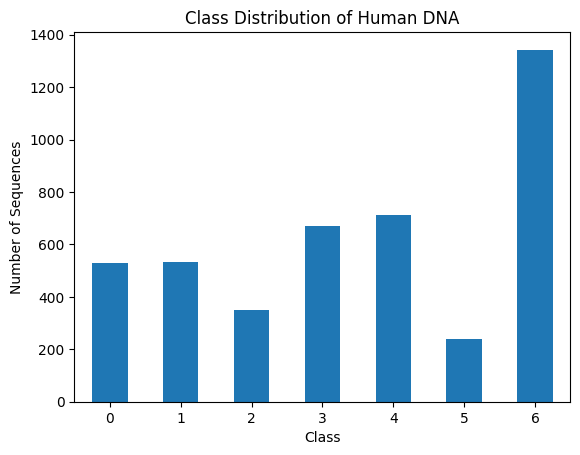

In [22]:
# ============================================================
# STEP: Class Distribution of Human DNA
# ============================================================

import matplotlib.pyplot as plt

# Count each class and create bar chart
human_dna['class'].value_counts().sort_index().plot.bar()

plt.title("Class Distribution of Human DNA")
plt.xlabel("Class")
plt.ylabel("Number of Sequences")
plt.xticks(rotation=0)
plt.show()

In [23]:
# ============================================================
# STEP: Load Chimpanzee DNA Dataset
# ============================================================

import pandas as pd

chimp_dna = pd.read_table(
    "/kaggle/input/datasets/nageshsingh/dna-sequence-dataset/chimpanzee.txt"
)

# Display first 5 rows
chimp_dna.head()

,sequence,class
0,ATGCCCCAACTAAATACCGCCGTATGACCCACCATAATTACCCCCA...,4
1,ATGAACGAAAATCTATTCGCTTCATTCGCTGCCCCCACAATCCTAG...,4
2,ATGGCCTCGCGCTGGTGGCGGTGGCGACGCGGCTGCTCCTGGAGGC...,4
3,ATGGCCTCGCGCTGGTGGCGGTGGCGACGCGGCTGCTCCTGGAGGC...,4
4,ATGGGCAGCGCCAGCCCGGGTCTGAGCAGCGTGTCCCCCAGCCACC...,6


In [24]:
print("Chimpanzee DNA Columns:")
print(chimp_dna.columns)

print("\nChimpanzee DNA Shape:")
print(chimp_dna.shape)

print("\nNumber of Rows:", chimp_dna.shape[0])
print("Number of Columns:", chimp_dna.shape[1])

Chimpanzee DNA Columns:
Index(['sequence', 'class'], dtype='object')

Chimpanzee DNA Shape:
(1682, 2)

Number of Rows: 1682
Number of Columns: 2


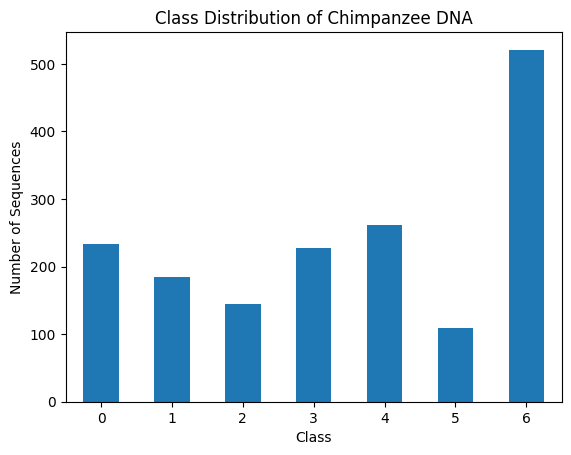

In [25]:
# ============================================================
# STEP: Class Distribution of Chimpanzee DNA
# ============================================================

import matplotlib.pyplot as plt

chimp_dna['class'].value_counts().sort_index().plot.bar()

plt.title("Class Distribution of Chimpanzee DNA")
plt.xlabel("Class")
plt.ylabel("Number of Sequences")
plt.xticks(rotation=0)
plt.show()

In [26]:
# ============================================================
# STEP: Load Dog DNA Dataset
# ============================================================

import pandas as pd

dog_dna = pd.read_table(
    "/kaggle/input/datasets/nageshsingh/dna-sequence-dataset/dog.txt"
)

# Display first 5 rows
dog_dna.head()

,sequence,class
0,ATGCCACAGCTAGATACATCCACCTGATTTATTATAATCTTTTCAA...,4
1,ATGAACGAAAATCTATTCGCTTCTTTCGCTGCCCCCTCAATAATAG...,4
2,ATGGAAACACCCTTCTACGGCGATGAGGCGCTGAGCGGCCTGGGCG...,6
3,ATGTGCACTAAAATGGAACAGCCCTTCTACCACGACGACTCATACG...,6
4,ATGAGCCGGCAGCTAAACAGAAGCCAGAACTGCTCCTTCAGTGACG...,0


In [27]:
print("Dog DNA Columns:")
print(dog_dna.columns)

print("\nDog DNA Shape:")
print(dog_dna.shape)

print("\nNumber of Rows:", dog_dna.shape[0])
print("Number of Columns:", dog_dna.shape[1])

Dog DNA Columns:
Index(['sequence', 'class'], dtype='object')

Dog DNA Shape:
(820, 2)

Number of Rows: 820
Number of Columns: 2


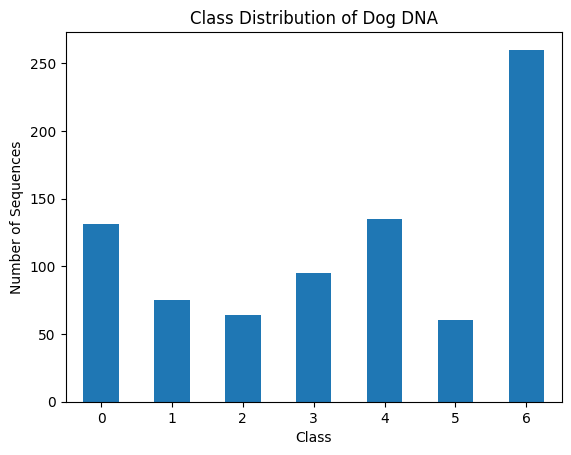

In [28]:
# ============================================================
# STEP: Class Distribution of Dog DNA
# ============================================================

import matplotlib.pyplot as plt

dog_dna['class'].value_counts().sort_index().plot.bar()

plt.title("Class Distribution of Dog DNA")
plt.xlabel("Class")
plt.ylabel("Number of Sequences")
plt.xticks(rotation=0)
plt.show()

In [29]:
# ============================================================
# STEP: Convert DNA Sequences into 6-mer Features
# ============================================================

def Kmers_funct(seq, size=6):
    """
    Convert a DNA sequence into overlapping k-mers.
    Default k-mer size = 6.
    """
    return [seq[x:x+size].lower() for x in range(len(seq) - size + 1)]


# ------------------------------------------------------------
# Human DNA: create 6-mer words
# ------------------------------------------------------------

human_dna['words'] = human_dna.apply(
    lambda x: Kmers_funct(x['sequence']),
    axis=1
)

# Remove original sequence column
human_dna = human_dna.drop('sequence', axis=1)


# ------------------------------------------------------------
# Chimpanzee DNA: create 6-mer words
# ------------------------------------------------------------

chimp_dna['words'] = chimp_dna.apply(
    lambda x: Kmers_funct(x['sequence']),
    axis=1
)

# Remove original sequence column
chimp_dna = chimp_dna.drop('sequence', axis=1)


# ------------------------------------------------------------
# Dog DNA: create 6-mer words
# ------------------------------------------------------------

dog_dna['words'] = dog_dna.apply(
    lambda x: Kmers_funct(x['sequence']),
    axis=1
)

# Remove original sequence column
dog_dna = dog_dna.drop('sequence', axis=1)


# ------------------------------------------------------------
# Check results
# ------------------------------------------------------------

print("Human DNA:")
print(human_dna.head())

print("\nChimpanzee DNA:")
print(chimp_dna.head())

print("\nDog DNA:")
print(dog_dna.head())

Human DNA:
   class                                              words
0      4  [atgccc, tgcccc, gcccca, ccccaa, cccaac, ccaac...
1      4  [atgaac, tgaacg, gaacga, aacgaa, acgaaa, cgaaa...
2      3  [atgtgt, tgtgtg, gtgtgg, tgtggc, gtggca, tggca...
3      3  [atgtgt, tgtgtg, gtgtgg, tgtggc, gtggca, tggca...
4      3  [atgcaa, tgcaac, gcaaca, caacag, aacagc, acagc...

Chimpanzee DNA:
   class                                              words
0      4  [atgccc, tgcccc, gcccca, ccccaa, cccaac, ccaac...
1      4  [atgaac, tgaacg, gaacga, aacgaa, acgaaa, cgaaa...
2      4  [atggcc, tggcct, ggcctc, gcctcg, cctcgc, ctcgc...
3      4  [atggcc, tggcct, ggcctc, gcctcg, cctcgc, ctcgc...
4      6  [atgggc, tgggca, gggcag, ggcagc, gcagcg, cagcg...

Dog DNA:
   class                                              words
0      4  [atgcca, tgccac, gccaca, ccacag, cacagc, acagc...
1      4  [atgaac, tgaacg, gaacga, aacgaa, acgaaa, cgaaa...
2      6  [atggaa, tggaaa, ggaaac, gaaaca, aaacac, aacac...
3 

In [30]:
print("Columns:", human_dna.columns.tolist())
print("Shape:", human_dna.shape)

human_dna.head()

Columns: ['class', 'words']
Shape: (4380, 2)


,class,words
0,4,"[atgccc, tgcccc, gcccca, ccccaa, cccaac, ccaac..."
1,4,"[atgaac, tgaacg, gaacga, aacgaa, acgaaa, cgaaa..."
2,3,"[atgtgt, tgtgtg, gtgtgg, tgtggc, gtggca, tggca..."
3,3,"[atgtgt, tgtgtg, gtgtgg, tgtggc, gtggca, tggca..."
4,3,"[atgcaa, tgcaac, gcaaca, caacag, aacagc, acagc..."


In [31]:
# ============================================================
# STEP: Prepare Human DNA K-mer Texts and Labels
# ============================================================

# Convert the list of 6-mers into a single space-separated string
human_texts = list(human_dna['words'])

for item in range(len(human_texts)):
    human_texts[item] = ' '.join(human_texts[item])


# ------------------------------------------------------------
# Separate labels
# ------------------------------------------------------------

# Extract the class labels
y_human = human_dna['class'].values


# ------------------------------------------------------------
# Check the results
# ------------------------------------------------------------

print("First Human DNA K-mer text:")
print(human_texts[0])

print("\nFirst Human DNA label:")
print(y_human[0])

print("\nNumber of Human DNA samples:", len(human_texts))
print("Number of Human DNA labels:", len(y_human))

First Human DNA K-mer text:
atgccc tgcccc gcccca ccccaa cccaac ccaact caacta aactaa actaaa ctaaat taaata aaatac aatact atacta tactac actacc ctaccg taccgt accgta ccgtat cgtatg gtatgg tatggc atggcc tggccc ggccca gcccac cccacc ccacca caccat accata ccataa cataat ataatt taatta aattac attacc ttaccc tacccc accccc ccccca ccccat cccata ccatac catact atactc tactcc actcct ctcctt tcctta ccttac cttaca ttacac tacact acacta cactat actatt ctattc tattcc attcct ttcctc tcctca cctcat ctcatc tcatca catcac atcacc tcaccc caccca acccaa cccaac ccaact caacta aactaa actaaa ctaaaa taaaaa aaaaat aaaata aaatat aatatt atatta tattaa attaaa ttaaac taaaca aaacac aacaca acacaa cacaaa acaaac caaact aaacta aactac actacc ctacca taccac accacc ccacct caccta acctac cctacc ctacct tacctc acctcc cctccc ctccct tccctc ccctca cctcac ctcacc tcacca caccaa accaaa ccaaag caaagc aaagcc aagccc agccca gcccat cccata ccataa cataaa ataaaa taaaaa aaaaat aaaata aaataa aataaa ataaaa taaaaa aaaaaa aaaaat aaaatt aaatta aattat attata ttataa tataac

In [32]:
# ============================================================
# STEP: Prepare Chimpanzee and Dog DNA K-mer Texts and Labels
# ============================================================

# ------------------------------------------------------------
# Chimpanzee DNA
# ------------------------------------------------------------

chimp_texts = list(chimp_dna['words'])

for item in range(len(chimp_texts)):
    chimp_texts[item] = ' '.join(chimp_texts[item])

# Separate labels
y_chim = chimp_dna['class'].values


# ------------------------------------------------------------
# Dog DNA
# ------------------------------------------------------------

dog_texts = list(dog_dna['words'])

for item in range(len(dog_texts)):
    dog_texts[item] = ' '.join(dog_texts[item])

# Separate labels
y_dog = dog_dna['class'].values


# ------------------------------------------------------------
# Check results
# ------------------------------------------------------------

print("Chimpanzee first K-mer text:")
print(chimp_texts[0])

print("\nChimpanzee first label:")
print(y_chim[0])

print("\nDog first K-mer text:")
print(dog_texts[0])

print("\nDog first label:")
print(y_dog[0])

print("\nNumber of Chimpanzee samples:", len(chimp_texts))
print("Number of Chimpanzee labels:", len(y_chim))

print("\nNumber of Dog samples:", len(dog_texts))
print("Number of Dog labels:", len(y_dog))

Chimpanzee first K-mer text:
atgccc tgcccc gcccca ccccaa cccaac ccaact caacta aactaa actaaa ctaaat taaata aaatac aatacc ataccg taccgc accgcc ccgccg cgccgt gccgta ccgtat cgtatg gtatga tatgac atgacc tgaccc gaccca acccac cccacc ccacca caccat accata ccataa cataat ataatt taatta aattac attacc ttaccc tacccc accccc ccccca ccccat cccata ccatac catact atactc tactcc actcct ctcctg tcctga cctgac ctgaca tgacac gacact acacta cactat actatt ctattt tatttc atttct tttctc ttctcg tctcgt ctcgtc tcgtca cgtcac gtcacc tcaccc caccca acccaa cccaac ccaact caacta aactaa actaaa ctaaaa taaaaa aaaaat aaaata aaatat aatatt atatta tattaa attaaa ttaaat taaatt aaattc aattca attcaa ttcaaa tcaaat caaatt aaatta aattac attacc ttacca taccat accatc ccatct catcta atctac tctacc ctaccc tacccc accccc cccccc ccccct cccctc ccctca cctcac ctcacc tcacca caccaa accaaa ccaaaa caaaac aaaacc aaaccc aaccca acccat cccata ccataa cataaa ataaaa taaaaa aaaaat aaaata aaataa aataaa ataaaa taaaaa aaaaaa aaaaac aaaact aaacta aactac actaca ctacaa tacaa

In [33]:
print("Human DNA Labels:")
print(y_human)

print("\nShape:", y_human.shape)

Human DNA Labels:
[4 4 3 ... 6 6 6]

Shape: (4380,)


In [34]:
from sklearn.feature_extraction.text import CountVectorizer

# Create 4-gram features
cv = CountVectorizer(ngram_range=(4, 4))

# Fit on Human DNA sequences
X = cv.fit_transform(human_texts)

# Transform Chimpanzee and Dog sequences using the same vocabulary
X_chimp = cv.transform(chimp_texts)
X_dog = cv.transform(dog_texts)

print("Human X shape:", X.shape)
print("Chimpanzee X shape:", X_chimp.shape)
print("Dog X shape:", X_dog.shape)

Human X shape: (4380, 232414)
Chimpanzee X shape: (1682, 232414)
Dog X shape: (820, 232414)


In [35]:
# ============================================================
# Split Human DNA Dataset into Training and Test Sets
# ============================================================

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_human,
    test_size=0.20,
    random_state=42
)

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)
print("Training labels shape:", y_train.shape)
print("Testing labels shape:", y_test.shape)

Training features shape: (3504, 232414)
Testing features shape: (876, 232414)
Training labels shape: (3504,)
Testing labels shape: (876,)


In [36]:
# ============================================================
# Train Multinomial Naive Bayes Classifier
# ============================================================

from sklearn.naive_bayes import MultinomialNB

# Create the classifier
classifier = MultinomialNB(alpha=0.1)

# Train the model
classifier.fit(X_train, y_train)

print("Multinomial Naive Bayes model trained successfully!")

Multinomial Naive Bayes model trained successfully!


In [37]:
# ============================================================
# Predict Human DNA Classes on Test Data
# ============================================================

y_pred = classifier.predict(X_test)

print("Predicted Labels:")
print(y_pred)

print("\nNumber of Predictions:", len(y_pred))

Predicted Labels:
[2 0 4 6 3 6 4 2 6 6 0 6 0 6 6 6 6 1 4 1 6 3 4 4 4 6 0 6 6 6 2 6 3 6 3 0 0
 6 3 4 3 0 6 5 3 0 6 6 1 2 1 3 0 5 0 5 2 6 4 1 5 1 4 4 4 4 4 3 4 2 2 3 4 5
 0 3 6 1 6 1 4 1 6 3 1 6 6 4 1 2 6 3 4 3 1 1 6 6 1 1 5 1 6 3 6 4 4 1 2 0 6
 3 5 4 6 6 5 6 6 6 3 0 0 4 4 1 2 0 4 6 5 2 5 6 1 2 4 4 6 1 3 2 3 5 6 6 1 5
 6 4 3 6 6 6 6 2 3 6 0 6 6 3 1 0 5 2 4 2 1 4 5 4 6 6 6 6 6 3 6 4 2 2 1 1 2
 6 6 6 6 0 4 0 4 2 1 2 3 0 6 4 6 1 2 1 4 4 3 5 6 6 6 0 4 1 0 1 3 3 5 0 6 0
 0 6 3 0 0 6 5 2 0 1 5 3 1 1 6 6 1 3 2 4 3 6 6 3 4 6 4 4 0 3 4 3 6 1 4 6 6
 6 6 0 0 6 6 6 6 4 4 3 3 1 4 6 4 6 4 2 3 2 6 3 3 6 2 6 6 1 1 5 0 5 3 1 3 6
 2 2 4 1 6 6 4 4 4 4 3 6 4 4 3 3 6 3 2 6 4 2 6 0 4 3 6 3 5 6 6 6 6 1 1 1 6
 1 3 5 3 4 1 6 0 1 4 5 5 5 3 0 6 4 0 0 0 6 3 4 4 1 0 3 6 5 4 3 4 3 3 4 6 2
 4 6 4 5 6 0 6 1 2 1 6 4 6 1 4 6 4 0 4 6 6 6 6 0 6 3 3 6 4 6 2 6 6 6 1 0 6
 3 0 4 6 6 4 6 6 6 1 6 6 1 3 0 0 2 6 0 5 6 0 4 6 3 1 4 3 6 3 2 6 2 2 6 6 5
 6 3 6 4 3 6 4 6 0 3 0 2 0 5 4 4 6 0 6 2 6 4 2 1 4 6 6 6 6 0 1 0 4 6 6 4 0
 1 6 4 

Confusion Matrix for Predictions on Human Test DNA Sequences

Predicted   0    1   2    3    4   5    6
Actual                                   
0          99    0   0    0    1   0    2
1           0  104   0    0    0   0    2
2           0    0  78    0    0   0    0
3           0    0   0  124    0   0    1
4           1    0   0    0  143   0    5
5           0    0   0    0    0  51    0
6           1    0   0    1    0   0  263


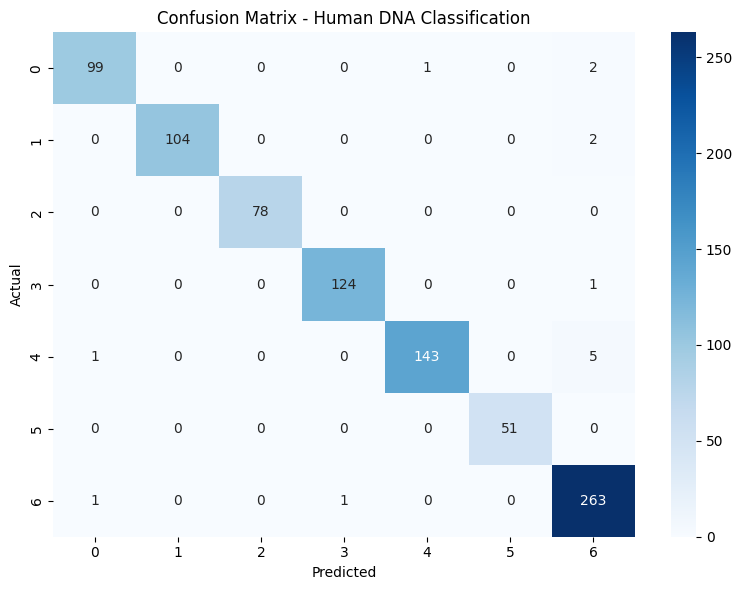


Model Performance:
--------------------------------
Accuracy  = 0.984
Precision = 0.984
Recall    = 0.984
F1 Score  = 0.984


In [40]:
# ============================================================
# Evaluate Multinomial Naive Bayes Model
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. Confusion Matrix
# ------------------------------------------------------------

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix for Predictions on Human Test DNA Sequences\n")

print(
    pd.crosstab(
        pd.Series(y_test, name='Actual'),
        pd.Series(y_pred, name='Predicted')
    )
)

# Colored Confusion Matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=sorted(set(y_test)),
    yticklabels=sorted(set(y_test))
)

plt.title("Confusion Matrix - Human DNA Classification")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 2. Evaluation Metrics
# ------------------------------------------------------------

def get_metrics(y_test, y_predicted):

    accuracy = accuracy_score(y_test, y_predicted)

    precision = precision_score(
        y_test,
        y_predicted,
        average='weighted',
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_predicted,
        average='weighted',
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_predicted,
        average='weighted',
        zero_division=0
    )

    return accuracy, precision, recall, f1


# Calculate metrics
accuracy, precision, recall, f1 = get_metrics(y_test, y_pred)


# ------------------------------------------------------------
# 3. Display Performance
# ------------------------------------------------------------

print("\nModel Performance:")
print("--------------------------------")
print("Accuracy  = %.3f" % accuracy)
print("Precision = %.3f" % precision)
print("Recall    = %.3f" % recall)
print("F1 Score  = %.3f" % f1)

In [41]:
# ============================================================
# Predicting Chimpanzee DNA Sequences
# ============================================================

y_pred_chimp = classifier.predict(X_chimp)

print("Predicted Chimpanzee DNA Labels:")
print(y_pred_chimp)

print("\nNumber of Chimpanzee Predictions:", len(y_pred_chimp))

Predicted Chimpanzee DNA Labels:
[4 4 4 ... 6 3 3]

Number of Chimpanzee Predictions: 1682


Confusion Matrix for Predictions on Chimpanzee DNA Sequences

Predicted    0    1    2    3    4    5    6
Actual                                      
0          232    0    0    0    0    0    2
1            0  184    0    0    0    0    1
2            0    0  144    0    0    0    0
3            0    0    0  227    0    0    1
4            2    0    0    0  254    0    5
5            0    0    0    0    0  109    0
6            0    0    0    0    0    0  521


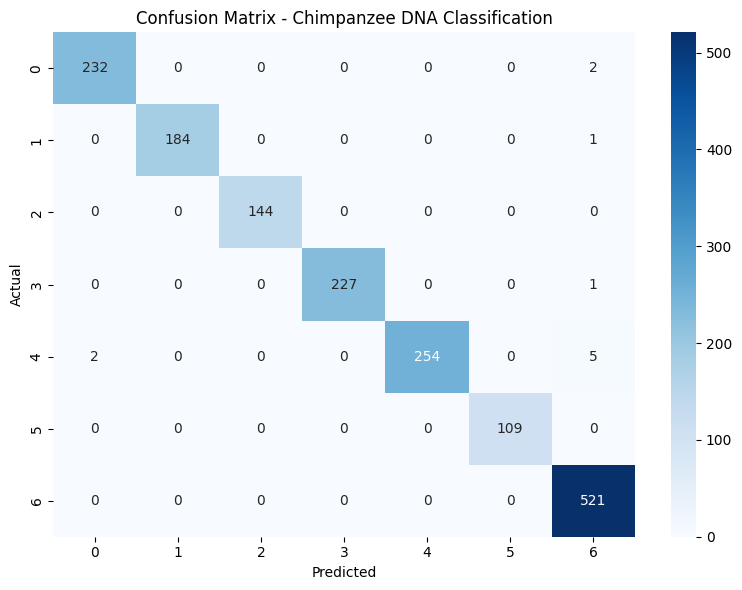


Chimpanzee DNA Model Performance:
-----------------------------------
Accuracy  = 0.993
Precision = 0.994
Recall    = 0.993
F1 Score  = 0.993


In [42]:
# ============================================================
# Performance Evaluation on Chimpanzee DNA Sequences
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# ------------------------------------------------------------
# 1. Confusion Matrix
# ------------------------------------------------------------

print("Confusion Matrix for Predictions on Chimpanzee DNA Sequences\n")

cm_chimp = confusion_matrix(y_chim, y_pred_chimp)

print(
    pd.crosstab(
        pd.Series(y_chim, name='Actual'),
        pd.Series(y_pred_chimp, name='Predicted')
    )
)

# Colored Confusion Matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_chimp,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=sorted(set(y_chim)),
    yticklabels=sorted(set(y_chim))
)

plt.title("Confusion Matrix - Chimpanzee DNA Classification")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 2. Calculate Performance Metrics
# ------------------------------------------------------------

accuracy, precision, recall, f1 = get_metrics(
    y_chim,
    y_pred_chimp
)


# ------------------------------------------------------------
# 3. Display Results
# ------------------------------------------------------------

print("\nChimpanzee DNA Model Performance:")
print("-----------------------------------")
print("Accuracy  = %.3f" % accuracy)
print("Precision = %.3f" % precision)
print("Recall    = %.3f" % recall)
print("F1 Score  = %.3f" % f1)

In [43]:
# ============================================================
# Predicting Dog DNA Sequences
# ============================================================

y_pred_dog = classifier.predict(X_dog)

print("Predicted Dog DNA Labels:")
print(y_pred_dog)

print("\nNumber of Dog Predictions:", len(y_pred_dog))

Predicted Dog DNA Labels:
[0 6 6 6 0 6 0 6 0 0 0 6 6 0 0 0 6 0 0 0 0 0 6 0 0 0 6 0 0 6 0 0 0 0 6 0 6
 0 6 6 6 0 6 0 6 0 0 3 3 6 6 6 6 4 0 0 4 2 0 0 0 0 6 0 6 0 0 5 5 6 4 6 0 0
 3 6 3 6 6 6 6 6 4 6 4 1 4 0 0 0 6 6 4 6 6 6 6 6 4 6 6 3 3 0 6 0 6 6 6 6 4
 4 5 6 6 1 5 6 6 1 4 2 6 3 3 6 6 6 3 3 6 6 6 3 6 6 2 0 0 6 6 3 3 3 0 0 4 6
 6 0 1 1 0 0 0 4 0 4 0 0 3 4 6 0 6 6 3 4 0 6 6 6 2 2 2 3 6 2 2 2 6 0 0 6 6
 0 0 6 6 5 5 6 0 6 0 0 4 0 0 3 4 0 0 6 6 5 5 6 4 1 0 6 5 6 6 4 4 2 2 2 4 6
 6 0 2 6 6 6 0 6 4 3 0 0 6 0 6 4 6 1 1 4 6 4 4 6 4 3 2 2 1 6 3 3 4 3 0 3 5
 5 5 5 5 5 5 2 2 4 4 6 4 4 6 6 6 0 3 3 4 3 0 0 6 0 0 6 6 1 0 5 0 0 6 6 1 1
 1 4 2 2 3 4 3 4 3 1 4 4 3 1 6 1 6 6 6 5 0 0 6 6 6 6 4 3 3 4 4 5 6 6 0 4 1
 2 4 4 3 4 4 0 0 6 0 5 4 6 4 4 6 5 3 3 6 6 6 6 6 3 0 0 6 6 3 6 0 0 2 6 4 4
 6 2 4 4 4 0 6 6 6 0 6 3 2 6 4 0 6 4 6 4 4 4 6 6 6 4 6 6 6 2 6 6 6 6 6 5 6
 0 0 0 5 5 5 4 6 6 6 6 1 1 6 6 1 4 1 1 3 6 6 1 6 2 2 0 0 4 6 0 0 5 0 1 6 4
 3 0 2 2 2 3 1 6 3 3 6 6 6 6 5 5 4 6 4 6 6 6 6 6 6 0 0 3 6 5 5 1 1 1 6 6 6

Confusion Matrix for Predictions on Dog DNA Sequences

Predicted    0   1   2   3    4   5    6
Actual                                  
0          127   0   0   0    0   0    4
1            0  63   0   0    1   0   11
2            0   0  49   0    1   0   14
3            1   0   0  81    2   0   11
4            4   0   0   1  126   0    4
5            4   0   0   0    1  53    2
6            0   0   0   0    0   0  260


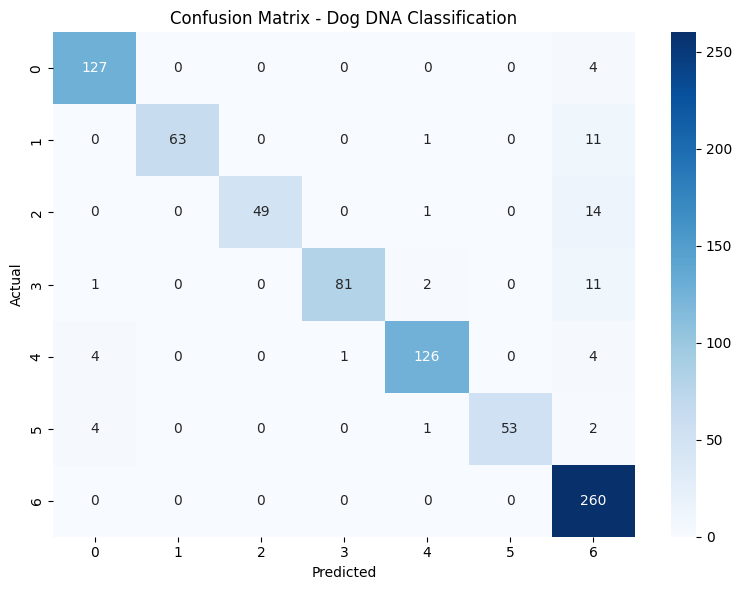


Dog DNA Model Performance:
--------------------------------
Accuracy  = 0.926
Precision = 0.934
Recall    = 0.926
F1 Score  = 0.925


In [44]:
# ============================================================
# Performance Evaluation on Dog DNA Sequences
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

# ------------------------------------------------------------
# 1. Confusion Matrix
# ------------------------------------------------------------

print("Confusion Matrix for Predictions on Dog DNA Sequences\n")

cm_dog = confusion_matrix(y_dog, y_pred_dog)

print(
    pd.crosstab(
        pd.Series(y_dog, name='Actual'),
        pd.Series(y_pred_dog, name='Predicted')
    )
)

# Colored Confusion Matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_dog,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=sorted(set(y_dog)),
    yticklabels=sorted(set(y_dog))
)

plt.title("Confusion Matrix - Dog DNA Classification")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 2. Calculate Performance Metrics
# ------------------------------------------------------------

accuracy, precision, recall, f1 = get_metrics(
    y_dog,
    y_pred_dog
)


# ------------------------------------------------------------
# 3. Display Results
# ------------------------------------------------------------

print("\nDog DNA Model Performance:")
print("--------------------------------")
print("Accuracy  = %.3f" % accuracy)
print("Precision = %.3f" % precision)
print("Recall    = %.3f" % recall)
print("F1 Score  = %.3f" % f1)

Model Performance Comparison
            Accuracy  Precision  Recall  F1 Score
Human          0.984      0.984   0.984     0.984
Chimpanzee     0.993      0.994   0.993     0.993
Dog            0.926      0.934   0.926     0.925


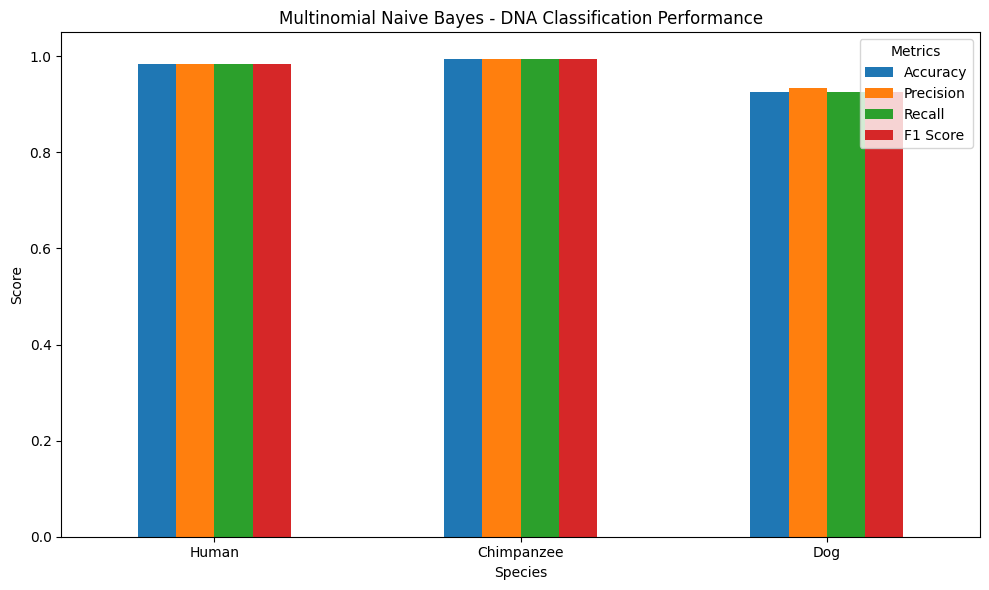

In [45]:
# ============================================================
# Model Comparison - DNA Sequence Classification
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# Calculate metrics for each species
human_metrics = get_metrics(y_test, y_pred)
chimp_metrics = get_metrics(y_chim, y_pred_chimp)
dog_metrics = get_metrics(y_dog, y_pred_dog)

# Create comparison table
comparison = pd.DataFrame(
    [human_metrics, chimp_metrics, dog_metrics],
    columns=['Accuracy', 'Precision', 'Recall', 'F1 Score'],
    index=['Human', 'Chimpanzee', 'Dog']
)

print("Model Performance Comparison")
print("============================")
print(comparison.round(3))


# ------------------------------------------------------------
# Bar Chart
# ------------------------------------------------------------

comparison.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title("Multinomial Naive Bayes - DNA Classification Performance")
plt.xlabel("Species")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(title="Metrics")
plt.tight_layout()
plt.show()

ROC-AUC Comparison
Human       AUC = 0.998
Chimpanzee  AUC = 0.999
Dog         AUC = 0.983


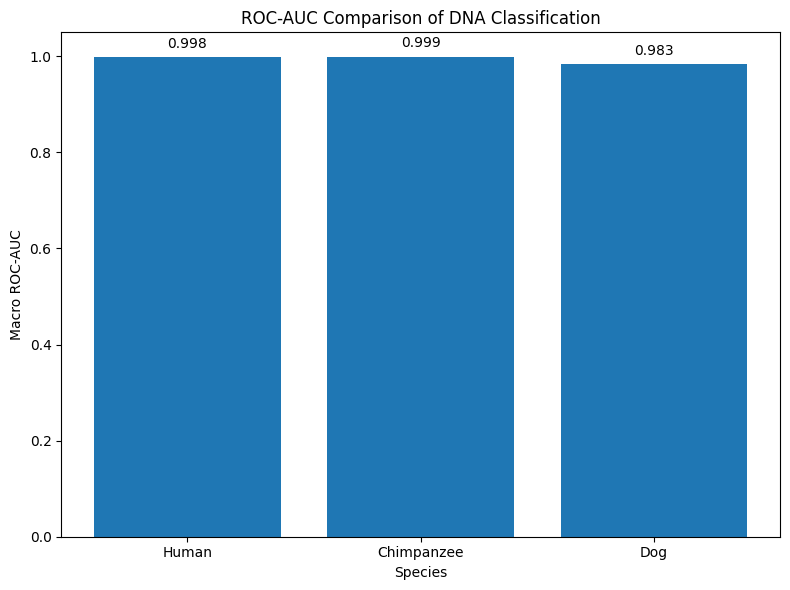

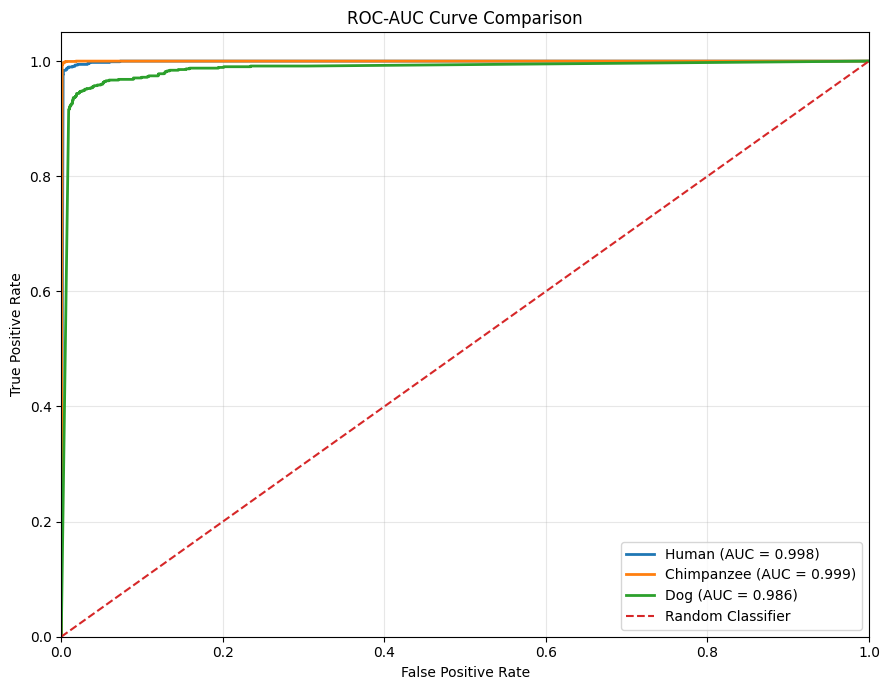

In [47]:
# ============================================================
# ROC-AUC Comparison: Human vs Chimpanzee vs Dog
# Multinomial Naive Bayes
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, roc_auc_score

# ============================================================
# 1. Get Prediction Probabilities
# ============================================================

# Human
y_score_human = classifier.predict_proba(X_test)

# Chimpanzee
y_score_chimp = classifier.predict_proba(X_chimp)

# Dog
y_score_dog = classifier.predict_proba(X_dog)


# ============================================================
# 2. Function to Calculate Macro ROC-AUC
# ============================================================

def calculate_macro_auc(y_true, y_score, classes):
    
    y_true_bin = label_binarize(y_true, classes=classes)
    
    auc_values = []
    
    for i in range(len(classes)):
        fpr, tpr, _ = roc_curve(
            y_true_bin[:, i],
            y_score[:, i]
        )
        
        auc_value = auc(fpr, tpr)
        auc_values.append(auc_value)
    
    return np.mean(auc_values)


# ============================================================
# 3. Calculate ROC-AUC for Each Dataset
# ============================================================

classes = classifier.classes_

auc_human = calculate_macro_auc(
    y_test,
    y_score_human,
    classes
)

auc_chimp = calculate_macro_auc(
    y_chim,
    y_score_chimp,
    classes
)

auc_dog = calculate_macro_auc(
    y_dog,
    y_score_dog,
    classes
)


# ============================================================
# 4. Comparison Table
# ============================================================

print("ROC-AUC Comparison")
print("===================")

print("Human       AUC =", round(auc_human, 3))
print("Chimpanzee  AUC =", round(auc_chimp, 3))
print("Dog         AUC =", round(auc_dog, 3))


# ============================================================
# 5. Bar Chart Comparison
# ============================================================

species = ['Human', 'Chimpanzee', 'Dog']
auc_scores = [auc_human, auc_chimp, auc_dog]

plt.figure(figsize=(8, 6))

bars = plt.bar(
    species,
    auc_scores
)

plt.title("ROC-AUC Comparison of DNA Classification")
plt.xlabel("Species")
plt.ylabel("Macro ROC-AUC")
plt.ylim(0, 1.05)

# Show values on bars
for bar, score in zip(bars, auc_scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{score:.3f}",
        ha='center'
    )

plt.tight_layout()
plt.show()


# ============================================================
# 6. Combined ROC Curve
# ============================================================

plt.figure(figsize=(9, 7))

# Function for micro-average ROC curve
def plot_micro_roc(y_true, y_score, classes, label):
    
    y_true_bin = label_binarize(
        y_true,
        classes=classes
    )
    
    fpr, tpr, _ = roc_curve(
        y_true_bin.ravel(),
        y_score.ravel()
    )
    
    roc_auc = auc(fpr, tpr)
    
    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f'{label} (AUC = {roc_auc:.3f})'
    )


# Plot all three
plot_micro_roc(
    y_test,
    y_score_human,
    classes,
    'Human'
)

plot_micro_roc(
    y_chim,
    y_score_chimp,
    classes,
    'Chimpanzee'
)

plot_micro_roc(
    y_dog,
    y_score_dog,
    classes,
    'Dog'
)


# Random classifier
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.title("ROC-AUC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.xlim([0, 1])
plt.ylim([0, 1.05])

plt.legend(loc='lower right')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()